       SMART MANUFACTURING COMMUNICATION PLATFORM
Simulation initialized successfully!

INDUSTRIAL SENSOR DATA
-----------------------------------------------------------------
Machine | Temperature | Pressure | Vibration
      1 |      53.09 °C |    1.28 bar |    3.21 mm/s
      2 |      96.30 °C |    6.73 bar |    0.42 mm/s
      3 |      79.90 °C |    3.83 bar |    0.81 mm/s
      4 |      69.90 °C |    5.58 bar |    4.49 mm/s
      5 |      36.70 °C |    9.17 bar |    3.03 mm/s
      6 |      36.70 °C |    3.24 bar |    0.05 mm/s
      7 |      29.36 °C |    4.69 bar |    0.51 mm/s
      8 |      89.96 °C |    7.80 bar |    3.32 mm/s
      9 |      70.08 °C |    3.06 bar |    0.03 mm/s
     10 |      78.11 °C |    1.69 bar |    0.80 mm/s

DATA ACQUISITION
-----------------------------------------------------------------
Original sensor values: [53 96 80 70 37 37 29 90 70 78]
Binary data (first 40 bits): [0 0 1 1 0 1 0 1 0 1 1 0 0 0 0 0 0 1 0 1 0 0 0 0 0 1 0 0 0 1 1 0 0 0 1 0 0
 1 0

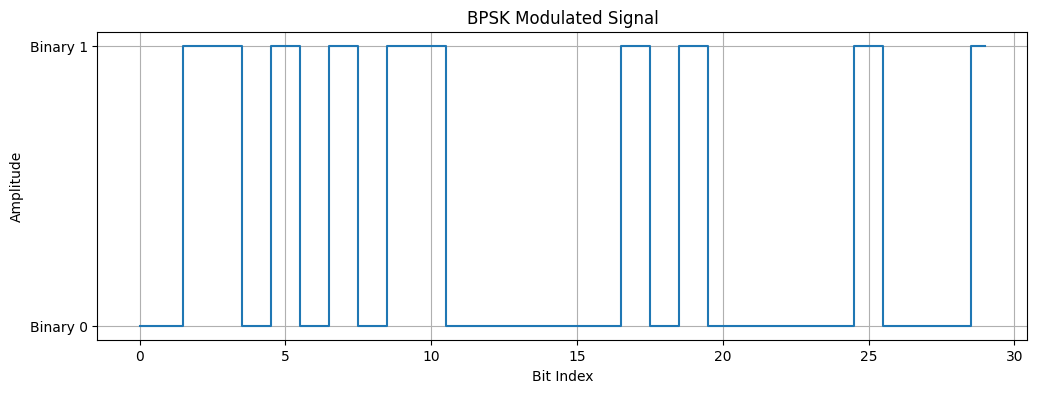


COMMUNICATION CHANNEL
-----------------------------------------------------------------
SNR: 5 dB
Transmitted signal: [-1 -1  1  1 -1  1 -1  1 -1  1  1 -1 -1 -1 -1]
Received signal: [-0.974 -1.366  2.206  1.356 -2.139  1.105 -1.372  1.479 -1.446  0.935
  1.284 -0.513 -1.675 -1.188 -1.267]

BPSK DEMODULATION
-----------------------------------------------------------------
Original bits: [0 0 1 1 0 1 0 1 0 1 1 0 0 0 0 0 0 1 0 1 0 0 0 0 0 1 0 0 0 1 1 0 0 0 1 0 0
 1 0 1]
Recovered bits: [0 0 1 1 0 1 0 1 0 1 1 0 0 0 0 0 0 1 0 1 1 0 0 0 0 1 0 0 0 1 0 0 0 0 1 0 0
 1 0 1]

DATA RECONSTRUCTION
-----------------------------------------------------------------
Original temperature values: [53 96 80 70 37 37 29 90 70 78]
Recovered temperature values: [53 96 88 68 37 37 25 90 70 78]

BIT ERROR RATE ANALYSIS
-----------------------------------------------------------------
Total transmitted bits: 800
Incorrectly received bits: 28
Bit Error Rate (BER): 0.035


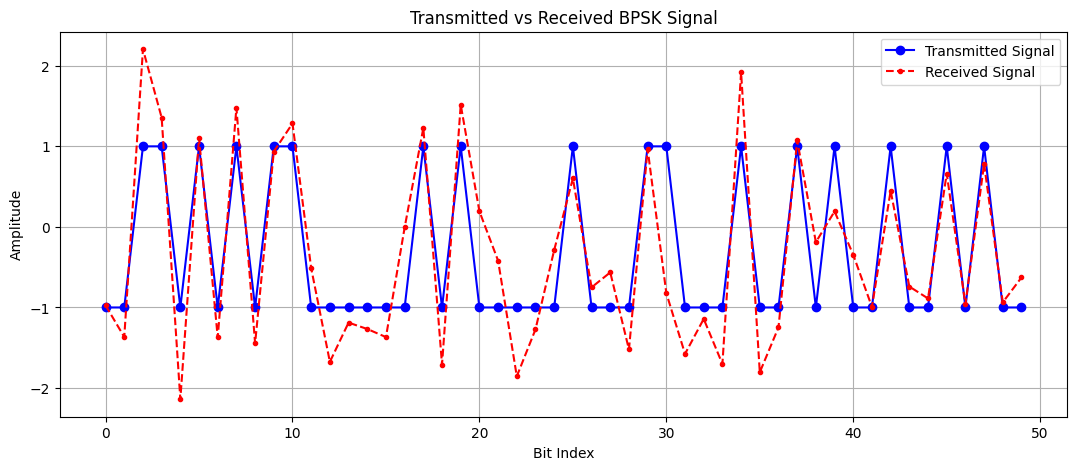

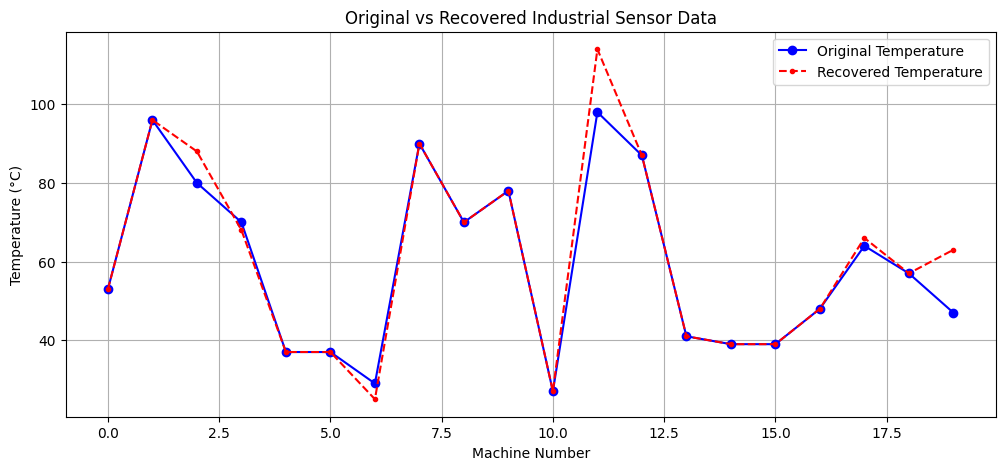

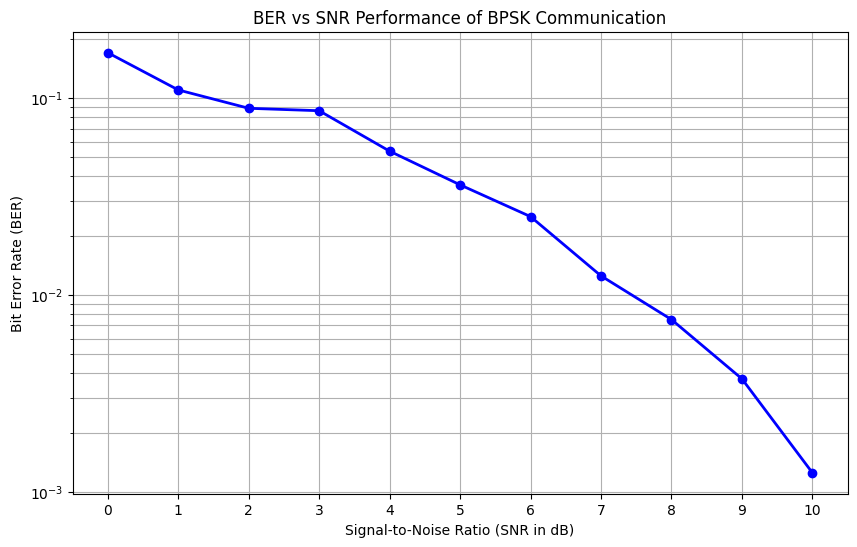


BER vs SNR RESULTS
-----------------------------------------------------------------
SNR (dB)       BER
0              0.170000
1              0.110000
2              0.088750
3              0.086250
4              0.053750
5              0.036250
6              0.025000
7              0.012500
8              0.007500
9              0.003750
10             0.000000

                  FINAL SIMULATION REPORT
Sensor Data Generation          : COMPLETED
Data Acquisition                 : COMPLETED
Binary Data Conversion           : COMPLETED
BPSK Modulation                  : COMPLETED
AWGN Channel Simulation          : COMPLETED
BPSK Demodulation                : COMPLETED
Data Reconstruction              : COMPLETED
BER Calculation                  : COMPLETED
BER vs SNR Analysis              : COMPLETED
-----------------------------------------------------------------
Total Transmitted Bits: 800
Bit Errors at 5 dB SNR: 28
BER at 5 dB SNR: 0.035
----------------------------------------

In [1]:

# ============================================================
# SMART MANUFACTURING COMMUNICATION PLATFORM
# ADC PBL PROJECT - COMPLETE PYTHON SIMULATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. PROJECT INITIALIZATION
# ------------------------------------------------------------

np.random.seed(42)

print("=" * 65)
print("       SMART MANUFACTURING COMMUNICATION PLATFORM")
print("=" * 65)
print("Simulation initialized successfully!\n")


# ------------------------------------------------------------
# 2. INDUSTRIAL SENSOR DATA GENERATION
# ------------------------------------------------------------

N = 100

temperature = np.random.uniform(25, 100, N)
pressure = np.random.uniform(1, 10, N)
vibration = np.random.uniform(0, 5, N)

print("INDUSTRIAL SENSOR DATA")
print("-" * 65)
print("Machine | Temperature | Pressure | Vibration")

for i in range(10):
    print(f"{i+1:7} | {temperature[i]:10.2f} °C | "
          f"{pressure[i]:7.2f} bar | {vibration[i]:7.2f} mm/s")


# ------------------------------------------------------------
# 3. DATA ACQUISITION AND BINARY CONVERSION
# ------------------------------------------------------------

sensor_values = np.round(temperature).astype(int)

binary_data = np.array([
    int(bit)
    for value in sensor_values
    for bit in format(value, '08b')
])

print("\nDATA ACQUISITION")
print("-" * 65)
print("Original sensor values:", sensor_values[:10])
print("Binary data (first 40 bits):", binary_data[:40])
print("Total transmitted bits:", len(binary_data))


# ------------------------------------------------------------
# 4. BPSK MODULATION
# ------------------------------------------------------------

# Binary 0 -> -1
# Binary 1 -> +1

bpsk_signal = 2 * binary_data - 1

print("\nBPSK MODULATION")
print("-" * 65)
print("Modulated signal (first 20 samples):")
print(bpsk_signal[:20])

plt.figure(figsize=(12, 4))
plt.step(range(30), bpsk_signal[:30], where='mid')
plt.title("BPSK Modulated Signal")
plt.xlabel("Bit Index")
plt.ylabel("Amplitude")
plt.yticks([-1, 1], ["Binary 0", "Binary 1"])
plt.grid(True)
plt.show()


# ------------------------------------------------------------
# 5. AWGN COMMUNICATION CHANNEL
# ------------------------------------------------------------

def awgn_channel(signal, snr_db):

    snr_linear = 10 ** (snr_db / 10)

    signal_power = np.mean(signal ** 2)

    noise_power = signal_power / snr_linear

    noise = np.sqrt(noise_power) * np.random.randn(len(signal))

    received_signal = signal + noise

    return received_signal


# Set initial SNR
snr_db = 5

received_signal = awgn_channel(bpsk_signal, snr_db)

print("\nCOMMUNICATION CHANNEL")
print("-" * 65)
print("SNR:", snr_db, "dB")
print("Transmitted signal:", bpsk_signal[:15])
print("Received signal:", np.round(received_signal[:15], 3))


# ------------------------------------------------------------
# 6. BPSK DEMODULATION
# ------------------------------------------------------------

received_bits = (received_signal >= 0).astype(int)

print("\nBPSK DEMODULATION")
print("-" * 65)
print("Original bits:", binary_data[:40])
print("Recovered bits:", received_bits[:40])


# ------------------------------------------------------------
# 7. DATA RECONSTRUCTION
# ------------------------------------------------------------

recovered_values = np.array([
    int(''.join(map(str, received_bits[i:i+8])), 2)
    for i in range(0, len(received_bits), 8)
])

print("\nDATA RECONSTRUCTION")
print("-" * 65)
print("Original temperature values:", sensor_values[:10])
print("Recovered temperature values:", recovered_values[:10])


# ------------------------------------------------------------
# 8. BIT ERROR RATE CALCULATION
# ------------------------------------------------------------

errors = np.sum(binary_data != received_bits)

ber = errors / len(binary_data)

print("\nBIT ERROR RATE ANALYSIS")
print("-" * 65)
print("Total transmitted bits:", len(binary_data))
print("Incorrectly received bits:", errors)
print("Bit Error Rate (BER):", ber)


# ------------------------------------------------------------
# 9. TRANSMITTED VS RECEIVED SIGNAL
# ------------------------------------------------------------

plt.figure(figsize=(13, 5))

plt.plot(bpsk_signal[:50], 'bo-', label="Transmitted Signal")
plt.plot(received_signal[:50], 'r.--', label="Received Signal")

plt.title("Transmitted vs Received BPSK Signal")
plt.xlabel("Bit Index")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()


# ------------------------------------------------------------
# 10. ORIGINAL VS RECOVERED SENSOR DATA
# ------------------------------------------------------------

plt.figure(figsize=(12, 5))

plt.plot(sensor_values[:20], 'bo-', label="Original Temperature")
plt.plot(recovered_values[:20], 'r.--', label="Recovered Temperature")

plt.title("Original vs Recovered Industrial Sensor Data")
plt.xlabel("Machine Number")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.show()


# ------------------------------------------------------------
# 11. BER VS SNR PERFORMANCE ANALYSIS
# ------------------------------------------------------------

snr_values = np.arange(0, 11, 1)

ber_values = []

for snr in snr_values:

    noisy_signal = awgn_channel(bpsk_signal, snr)

    decoded_bits = (noisy_signal >= 0).astype(int)

    error_count = np.sum(binary_data != decoded_bits)

    ber_value = error_count / len(binary_data)

    ber_values.append(ber_value)


plt.figure(figsize=(10, 6))

# Replace zero only for logarithmic display
plot_ber = np.maximum(ber_values, 1 / len(binary_data))

plt.semilogy(snr_values, plot_ber, 'bo-', linewidth=2)

plt.title("BER vs SNR Performance of BPSK Communication")
plt.xlabel("Signal-to-Noise Ratio (SNR in dB)")
plt.ylabel("Bit Error Rate (BER)")
plt.xticks(snr_values)
plt.grid(True, which="both")
plt.show()


print("\nBER vs SNR RESULTS")
print("-" * 65)
print("SNR (dB)       BER")

for snr, value in zip(snr_values, ber_values):
    print(f"{snr:<15}{value:.6f}")


# ------------------------------------------------------------
# 12. FINAL PERFORMANCE SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("                  FINAL SIMULATION REPORT")
print("=" * 65)

print("Sensor Data Generation          : COMPLETED")
print("Data Acquisition                 : COMPLETED")
print("Binary Data Conversion           : COMPLETED")
print("BPSK Modulation                  : COMPLETED")
print("AWGN Channel Simulation          : COMPLETED")
print("BPSK Demodulation                : COMPLETED")
print("Data Reconstruction              : COMPLETED")
print("BER Calculation                  : COMPLETED")
print("BER vs SNR Analysis              : COMPLETED")

print("-" * 65)

print("Total Transmitted Bits:", len(binary_data))
print("Bit Errors at 5 dB SNR:", errors)
print("BER at 5 dB SNR:", ber)

print("-" * 65)

if errors == 0:
    print("All bits were recovered correctly in this trial.")
else:
    print("Some transmission errors occurred.")

print("=" * 65)
print("       SIMULATION EXECUTION COMPLETED SUCCESSFULLY")
print("=" * 65)


Total sensor readings: 1000
Total data bits: 8000
BER calculations completed.


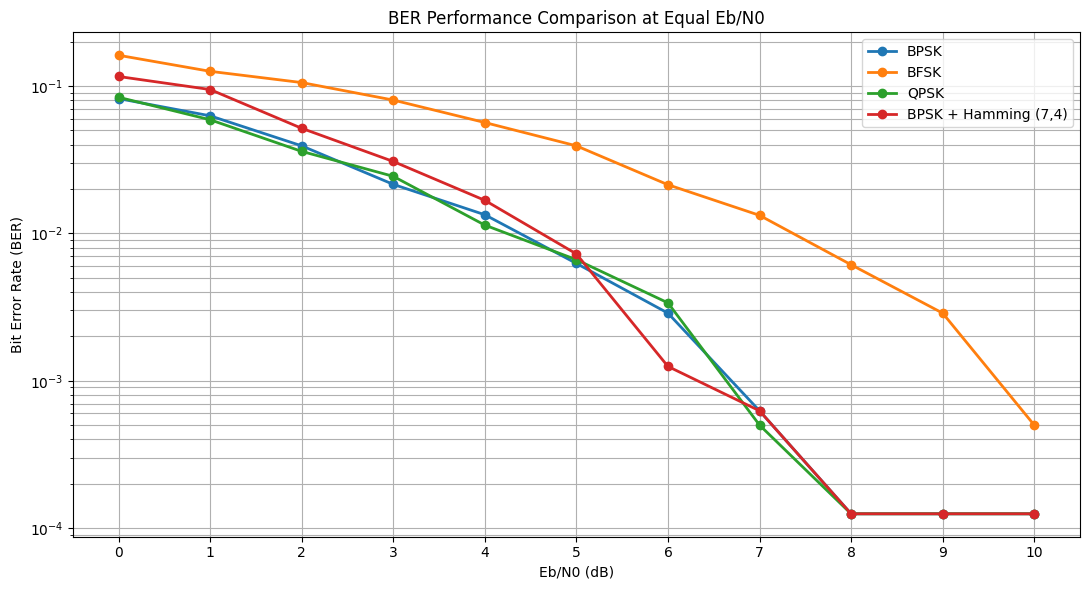

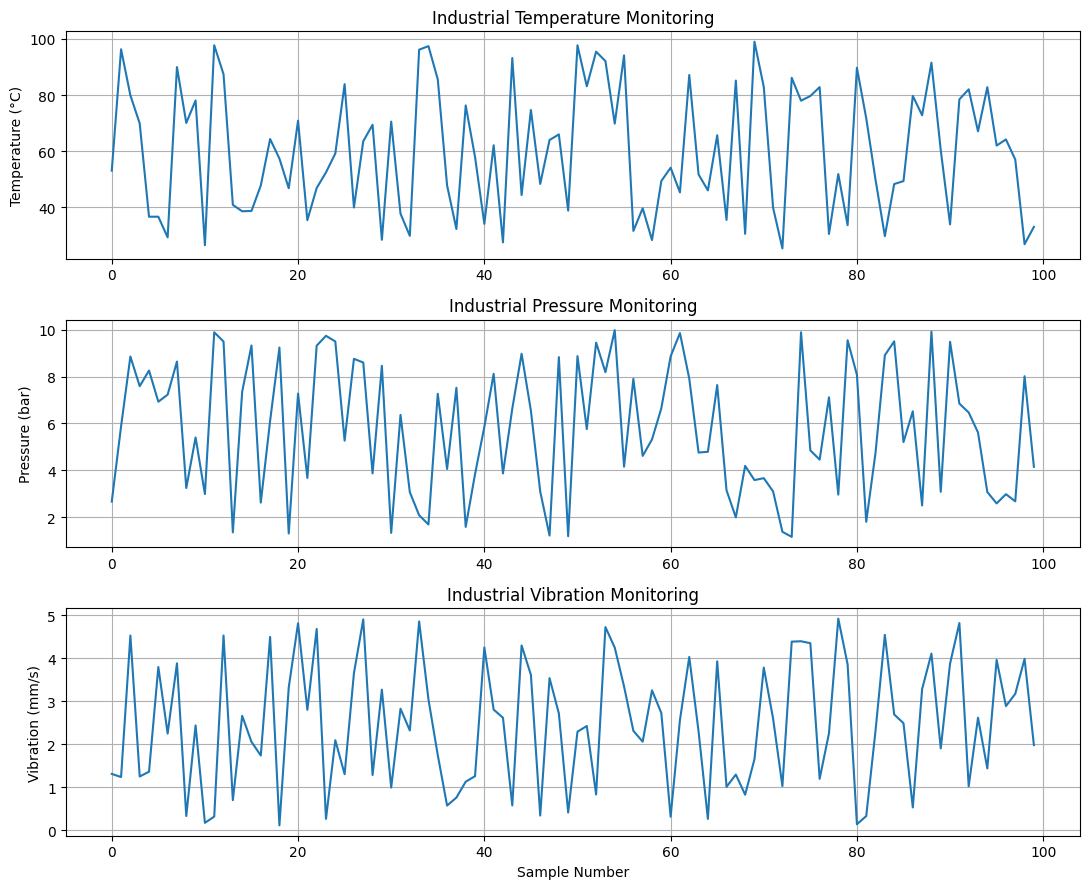


       SMART MANUFACTURING COMMUNICATION PLATFORM
             FINAL SIMULATION RESULTS
Total Sensor Readings: 1000
Total Original Bits: 8000

BER PERFORMANCE COMPARISON
-------------------------------------------------------------------------------------
Eb/N0 (dB)   BPSK           BFSK           QPSK           BPSK + Hamming      
0            0.082125       0.161625       0.083875       0.116000            
1            0.062750       0.125750       0.059000       0.094625            
2            0.039250       0.105500       0.036000       0.051625            
3            0.021500       0.080250       0.024375       0.030750            
4            0.013375       0.056500       0.011375       0.016750            
5            0.006250       0.039250       0.006625       0.007250            
6            0.002875       0.021375       0.003375       0.001250            
7            0.000625       0.013250       0.000500       0.000625            
8            0.000125       0.00

In [3]:

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# ==========================================================
# 1. INDUSTRIAL SENSOR DATA
# ==========================================================

N = 1000

temperature = np.random.uniform(25, 100, N)
pressure = np.random.uniform(1, 10, N)
vibration = np.random.uniform(0, 5, N)

sensor_values = np.round(temperature).astype(int)

bits = np.array([
    int(b)
    for value in sensor_values
    for b in format(value, "08b")
])

print("Total sensor readings:", N)
print("Total data bits:", len(bits))


# ==========================================================
# 2. AWGN CHANNEL
# ==========================================================

def add_awgn(signal, snr_db):
    snr = 10 ** (snr_db / 10)
    power = np.mean(np.abs(signal) ** 2)
    noise_power = power / snr

    noise = np.sqrt(noise_power / 2) * (
        np.random.randn(*signal.shape)
        + 1j * np.random.randn(*signal.shape)
    )

    return signal + noise


# ==========================================================
# 3. BPSK MODULATION AND DEMODULATION
# ==========================================================

def bpsk_mod(data):
    return 2 * data - 1

def bpsk_demod(signal):
    return (np.real(signal) >= 0).astype(int)


# ==========================================================
# 4. BFSK MODULATION AND DEMODULATION
# ==========================================================

def bfsk_mod(data):
    # Orthogonal complex BFSK symbols
    return np.where(data == 1, 1+0j, 0+1j)

def bfsk_demod(signal):
    return (np.real(signal) > np.imag(signal)).astype(int)


# ==========================================================
# 5. QPSK MODULATION AND DEMODULATION
# ==========================================================

def qpsk_mod(data):
    padded = np.append(data, 0) if len(data) % 2 else data
    pairs = padded.reshape(-1, 2)

    # Gray-coded QPSK
    i = 2 * pairs[:, 0] - 1
    q = 2 * pairs[:, 1] - 1

    return (i + 1j*q) / np.sqrt(2), len(data)

def qpsk_demod(signal, original_length):
    decoded_i = (np.real(signal) >= 0).astype(int)
    decoded_q = (np.imag(signal) >= 0).astype(int)

    decoded = np.column_stack((decoded_i, decoded_q)).flatten()
    return decoded[:original_length]


# ==========================================================
# 6. HAMMING (7,4) ERROR CONTROL CODING
# ==========================================================

def hamming_encode(data):
    padded = np.pad(data, (0, (-len(data)) % 4))
    groups = padded.reshape(-1, 4)

    d1, d2, d3, d4 = groups.T

    p1 = d1 ^ d2 ^ d4
    p2 = d1 ^ d3 ^ d4
    p3 = d2 ^ d3 ^ d4

    code = np.column_stack([
        p1, p2, d1, p3, d2, d3, d4
    ])

    return code.flatten(), len(data)


def hamming_decode(code, original_length):
    groups = code.reshape(-1, 7).copy()

    for g in groups:
        p1, p2, d1, p3, d2, d3, d4 = g

        s1 = p1 ^ d1 ^ d2 ^ d4
        s2 = p2 ^ d1 ^ d3 ^ d4
        s3 = p3 ^ d2 ^ d3 ^ d4

        error_position = s1 + 2*s2 + 4*s3

        if error_position:
            g[error_position - 1] ^= 1

    decoded = groups[:, [2, 4, 5, 6]].flatten()

    return decoded[:original_length]

# ============================================================
# 7. BER PERFORMANCE COMPARISON
# BPSK vs BFSK vs QPSK vs BPSK + HAMMING (7,4)
# ============================================================

snr_values = np.arange(0, 11, 1)

ber_bpsk = []
ber_bfsk = []
ber_qpsk = []
ber_hamming = []

R = 4 / 7  # Hamming code rate

for ebn0_db in snr_values:

    gamma = 10 ** (ebn0_db / 10)
    N0 = 1 / gamma

    # BPSK
    tx = bpsk_mod(bits).astype(float)
    noise = np.sqrt(N0 / 2) * np.random.randn(len(tx))
    rx = tx + noise
    decoded = (rx >= 0).astype(int)
    ber_bpsk.append(np.mean(bits != decoded))

    # BFSK: orthogonal complex signalling
    tx = bfsk_mod(bits)
    noise = np.sqrt(N0 / 2) * (
        np.random.randn(len(tx)) +
        1j * np.random.randn(len(tx))
    )
    rx = tx + noise
    decoded = bfsk_demod(rx)
    ber_bfsk.append(np.mean(bits != decoded))

    # QPSK
    tx, original_length = qpsk_mod(bits)
    tx = tx * np.sqrt(2)

    noise = np.sqrt(N0 / 2) * (
        np.random.randn(len(tx)) +
        1j * np.random.randn(len(tx))
    )
    rx = tx + noise
    decoded = qpsk_demod(rx / np.sqrt(2), original_length)
    ber_qpsk.append(np.mean(bits != decoded))

    # BPSK + Hamming (7,4)
    encoded, original_length = hamming_encode(bits)
    tx = np.sqrt(R) * bpsk_mod(encoded)

    noise = np.sqrt(N0 / 2) * np.random.randn(len(tx))
    rx = tx + noise

    received = (rx >= 0).astype(int)
    recovered = hamming_decode(received, original_length)

    ber_hamming.append(np.mean(bits != recovered))

print("BER calculations completed.")


# ==========================================================
# 8. BER VS SNR GRAPH
# ==========================================================

plt.figure(figsize=(11, 6))

curves = [
    ("BPSK", ber_bpsk),
    ("BFSK", ber_bfsk),
    ("QPSK", ber_qpsk),
    ("BPSK + Hamming (7,4)", ber_hamming)
]

for name, values in curves:
    plt.semilogy(
        snr_values,
        np.maximum(values, 1 / len(bits)),
        marker='o',
        linewidth=2,
        label=name
    )

plt.title("BER Performance Comparison at Equal Eb/N0")
plt.xlabel("Eb/N0 (dB)")
plt.ylabel("Bit Error Rate (BER)")
plt.xticks(snr_values)
plt.grid(True, which="both")
plt.legend()
plt.tight_layout()
plt.show()



# ==========================================================
# 9. SENSOR MONITORING DASHBOARD
# ==========================================================

fig, axes = plt.subplots(3, 1, figsize=(11, 9))

axes[0].plot(temperature[:100])
axes[0].set_title("Industrial Temperature Monitoring")
axes[0].set_ylabel("Temperature (°C)")
axes[0].grid(True)

axes[1].plot(pressure[:100])
axes[1].set_title("Industrial Pressure Monitoring")
axes[1].set_ylabel("Pressure (bar)")
axes[1].grid(True)

axes[2].plot(vibration[:100])
axes[2].set_title("Industrial Vibration Monitoring")
axes[2].set_ylabel("Vibration (mm/s)")
axes[2].set_xlabel("Sample Number")
axes[2].grid(True)

plt.tight_layout()
plt.show()

# ============================================================
# 10. FINAL SIMULATION RESULTS
# ============================================================

print("\n" + "=" * 85)
print("       SMART MANUFACTURING COMMUNICATION PLATFORM")
print("             FINAL SIMULATION RESULTS")
print("=" * 85)

print("Total Sensor Readings:", N)
print("Total Original Bits:", len(bits))

print("\nBER PERFORMANCE COMPARISON")
print("-" * 85)

print(f"{'Eb/N0 (dB)':<13}{'BPSK':<15}{'BFSK':<15}"
      f"{'QPSK':<15}{'BPSK + Hamming':<20}")

for i, snr in enumerate(snr_values):
    print(
        f"{snr:<13}"
        f"{ber_bpsk[i]:<15.6f}"
        f"{ber_bfsk[i]:<15.6f}"
        f"{ber_qpsk[i]:<15.6f}"
        f"{ber_hamming[i]:<20.6f}"
    )

print("-" * 85)
print("SIMULATION STATUS: COMPLETED")
print("=" * 85)



In [4]:

# ============================================================
# MODULE 1: INDUSTRIAL SENSOR DATA PACKET FORMATION
# ============================================================

import numpy as np
import struct

# Each packet contains:
# Machine ID       : 1 byte
# Sequence Number  : 2 bytes
# Temperature      : 2 bytes
# Pressure         : 2 bytes
# Vibration        : 2 bytes

machine_id = 1

packets = []

for i in range(N):

    temp = int(round(temperature[i] * 100))
    press = int(round(pressure[i] * 100))
    vib = int(round(vibration[i] * 100))

    packet = struct.pack(
        ">BHHHH",
        machine_id,
        i,
        temp,
        press,
        vib
    )

    packets.append(packet)

# Combine all packets
packet_data = b"".join(packets)

# Convert packet bytes into binary bits
packet_bits = np.unpackbits(
    np.frombuffer(packet_data, dtype=np.uint8)
)

# ============================================================
# DISPLAY RESULTS
# ============================================================

print("=" * 60)
print("INDUSTRIAL DATA PACKET FORMATION")
print("=" * 60)

print("Total sensor readings:", N)
print("Total packets generated:", len(packets))
print("Bytes per packet:", len(packets[0]))
print("Total packet data bytes:", len(packet_data))
print("Total transmitted bits:", len(packet_bits))

print("\nFIRST 5 PACKETS")
print("-" * 60)

for i in range(5):

    decoded = struct.unpack(">BHHHH", packets[i])

    print(
        f"Packet {i+1}: "
        f"Machine ID={decoded[0]}, "
        f"Sequence={decoded[1]}, "
        f"Temperature={decoded[2]/100:.2f} °C, "
        f"Pressure={decoded[3]/100:.2f} bar, "
        f"Vibration={decoded[4]/100:.2f} mm/s"
    )

# ============================================================
# PACKET VALIDATION
# ============================================================

assert len(packets) == N
assert len(packet_bits) == N * 9 * 8

print("\nPacket validation: PASSED")
print("All three sensor readings included successfully.")


INDUSTRIAL DATA PACKET FORMATION
Total sensor readings: 1000
Total packets generated: 1000
Bytes per packet: 9
Total packet data bytes: 9000
Total transmitted bits: 72000

FIRST 5 PACKETS
------------------------------------------------------------
Packet 1: Machine ID=1, Sequence=0, Temperature=53.09 °C, Pressure=2.67 bar, Vibration=1.31 mm/s
Packet 2: Machine ID=1, Sequence=1, Temperature=96.30 °C, Pressure=5.88 bar, Vibration=1.23 mm/s
Packet 3: Machine ID=1, Sequence=2, Temperature=79.90 °C, Pressure=8.86 bar, Vibration=4.53 mm/s
Packet 4: Machine ID=1, Sequence=3, Temperature=69.90 °C, Pressure=7.59 bar, Vibration=1.25 mm/s
Packet 5: Machine ID=1, Sequence=4, Temperature=36.70 °C, Pressure=8.26 bar, Vibration=1.36 mm/s

Packet validation: PASSED
All three sensor readings included successfully.


In [5]:

# ============================================================
# MODULE 2: CRC-16 ERROR DETECTION
# ============================================================

# CRC-16-CCITT parameters
POLYNOMIAL = 0x1021
INITIAL_VALUE = 0xFFFF


# ------------------------------------------------------------
# 1. CRC GENERATION
# ------------------------------------------------------------

def calculate_crc(data):

    crc = INITIAL_VALUE

    for byte in data:

        crc ^= (byte << 8)

        for _ in range(8):

            if crc & 0x8000:
                crc = ((crc << 1) ^ POLYNOMIAL) & 0xFFFF
            else:
                crc = (crc << 1) & 0xFFFF

    return crc


# ------------------------------------------------------------
# 2. APPEND CRC TO EACH PACKET
# ------------------------------------------------------------

packets_with_crc = []

for packet in packets:

    crc_value = calculate_crc(packet)

    crc_bytes = struct.pack(">H", crc_value)

    protected_packet = packet + crc_bytes

    packets_with_crc.append(protected_packet)


# ------------------------------------------------------------
# 3. RECEIVER-SIDE CRC VERIFICATION
# ------------------------------------------------------------

def verify_crc(received_packet):

    if len(received_packet) < 2:
        return False

    received_data = received_packet[:-2]

    received_crc = struct.unpack(
        ">H", received_packet[-2:]
    )[0]

    calculated_crc = calculate_crc(received_data)

    return received_crc == calculated_crc


# ------------------------------------------------------------
# 4. VERIFY ALL ORIGINAL PACKETS
# ------------------------------------------------------------

valid_count = 0
invalid_count = 0

for packet in packets_with_crc:

    if verify_crc(packet):
        valid_count += 1
    else:
        invalid_count += 1


# ------------------------------------------------------------
# 5. SIMULATE TRANSMISSION ERROR
# ------------------------------------------------------------

# Copy one protected packet
test_packet = bytearray(packets_with_crc[0])

# Introduce an intentional bit error
test_packet[3] ^= 0b00000001

error_detected = not verify_crc(bytes(test_packet))


# ------------------------------------------------------------
# 6. DISPLAY RESULTS
# ------------------------------------------------------------

print("=" * 60)
print("CRC-16 ERROR DETECTION RESULTS")
print("=" * 60)

print("Total protected packets:", len(packets_with_crc))
print("Valid packets:", valid_count)
print("Invalid packets:", invalid_count)

print("\nPACKET VALIDATION")
print("-" * 60)

print("Original packet CRC verification:",
      verify_crc(packets_with_crc[0]))

print("CRC value:",
      hex(calculate_crc(packets[0])))

print("\nTRANSMISSION ERROR TEST")
print("-" * 60)

print("Intentional bit error introduced: YES")
print("Corrupted packet CRC verification:",
      verify_crc(bytes(test_packet)))
print("Error detected:", error_detected)

print("\nPACKET SIZE")
print("-" * 60)

print("Original packet size:", len(packets[0]), "bytes")
print("CRC size: 2 bytes")
print("Protected packet size:",
      len(packets_with_crc[0]), "bytes")

assert valid_count == N
assert invalid_count == 0
assert error_detected

print("\nCRC VALIDATION: PASSED")


CRC-16 ERROR DETECTION RESULTS
Total protected packets: 1000
Valid packets: 1000
Invalid packets: 0

PACKET VALIDATION
------------------------------------------------------------
Original packet CRC verification: True
CRC value: 0xc79e

TRANSMISSION ERROR TEST
------------------------------------------------------------
Intentional bit error introduced: YES
Corrupted packet CRC verification: False
Error detected: True

PACKET SIZE
------------------------------------------------------------
Original packet size: 9 bytes
CRC size: 2 bytes
Protected packet size: 11 bytes

CRC VALIDATION: PASSED


In [11]:

# ============================================================
# MODULE 3: CORRECTED END-TO-END COMMUNICATION
# ============================================================

np.random.seed(42)

# 1. TRANSMITTER: PROTECTED PACKETS

tx_data = b"".join(packets_with_crc)

tx_bits = np.unpackbits(
    np.frombuffer(tx_data, dtype=np.uint8)
).astype(int)

# 2. HAMMING ENCODING

encoded_bits, original_length = hamming_encode(tx_bits)

# 3. BPSK MODULATION

R = 4 / 7
EbN0_dB = 10

gamma = 10 ** (EbN0_dB / 10)
N0 = 1 / gamma

tx_signal = np.sqrt(R) * bpsk_mod(encoded_bits)

# 4. AWGN CHANNEL

noise = np.sqrt(N0 / 2) * np.random.randn(len(tx_signal))

rx_signal = tx_signal + noise

# 5. BPSK DEMODULATION

received_encoded_bits = (
    rx_signal >= 0
).astype(int)

# 6. HAMMING DECODING

recovered_bits = hamming_decode(
    received_encoded_bits.copy(),
    original_length
)

# 7. BIT ERROR ANALYSIS

bit_errors = np.sum(tx_bits != recovered_bits)

end_to_end_ber = bit_errors / len(tx_bits)

# 8. RECONSTRUCT RECEIVED PACKETS

received_bytes = np.packbits(
    recovered_bits
).tobytes()

packet_size = 11

received_packets = [
    received_bytes[i:i + packet_size]
    for i in range(0, len(received_bytes), packet_size)
]

# 9. CRC VERIFICATION

valid_packets = 0
corrupted_packets = 0

for packet in received_packets:

    if len(packet) == packet_size and verify_crc(packet):
        valid_packets += 1
    else:
        corrupted_packets += 1

# 10. PACKET DELIVERY RATIO

packet_delivery_ratio = (
    valid_packets / len(packets_with_crc)
) * 100

# 11. FINAL RESULTS

print("=" * 65)
print("SMART MANUFACTURING COMMUNICATION PLATFORM")
print("END-TO-END COMMUNICATION RESULTS")
print("=" * 65)

print("Original data bits:", len(tx_bits))
print("Encoded bits:", len(encoded_bits))
print("Operating Eb/N0:", EbN0_dB, "dB")

print("\nTRANSMISSION PERFORMANCE")
print("-" * 65)

print("Bit errors after decoding:", bit_errors)
print("End-to-end BER:", round(end_to_end_ber, 8))

print("\nPACKET VERIFICATION")
print("-" * 65)

print("Total transmitted packets:", len(packets_with_crc))
print("Valid packets received:", valid_packets)
print("Corrupted packets:", corrupted_packets)

print(
    "Packet delivery ratio:",
    round(packet_delivery_ratio, 2), "%"
)

print("\nEND-TO-END SIMULATION COMPLETED")

assert bit_errors == 0, "Unexpected decoded bit errors"
assert valid_packets == len(packets_with_crc), "Packet verification failed"


SMART MANUFACTURING COMMUNICATION PLATFORM
END-TO-END COMMUNICATION RESULTS
Original data bits: 88000
Encoded bits: 154000
Operating Eb/N0: 10 dB

TRANSMISSION PERFORMANCE
-----------------------------------------------------------------
Bit errors after decoding: 0
End-to-end BER: 0.0

PACKET VERIFICATION
-----------------------------------------------------------------
Total transmitted packets: 1000
Valid packets received: 1000
Corrupted packets: 0
Packet delivery ratio: 100.0 %

END-TO-END SIMULATION COMPLETED


In [9]:

# ============================================================
# DIAGNOSTIC TEST: BPSK AND HAMMING
# ============================================================

print("TEST 1: BPSK MODULATION")

test_bits = np.array([0, 1, 0, 1], dtype=np.uint8)

test_signal = bpsk_mod(test_bits)

print("Input bits:", test_bits)
print("Modulated signal:", test_signal)

print("\nTEST 2: HAMMING ENCODING AND DECODING")

test_data = np.random.randint(0, 2, 1000, dtype=np.uint8)

test_encoded, test_length = hamming_encode(test_data)

test_decoded = hamming_decode(
    test_encoded.copy(), test_length
)

errors = np.sum(test_data != test_decoded)

print("Original bits:", len(test_data))
print("Encoded bits:", len(test_encoded))
print("Errors without noise:", errors)

print("\nTEST 3: HAMMING WITH BPSK AND NO NOISE")

safe_signal = np.where(
    test_encoded == 1, 1.0, -1.0
)

received_bits = (safe_signal >= 0).astype(int)

recovered_bits = hamming_decode(
    received_bits, test_length
)

errors_no_noise = np.sum(
    test_data != recovered_bits
)

print("Errors without channel noise:", errors_no_noise)

print("\nDIAGNOSTIC COMPLETED")


TEST 1: BPSK MODULATION
Input bits: [0 1 0 1]
Modulated signal: [-1.  1. -1.  1.]

TEST 2: HAMMING ENCODING AND DECODING
Original bits: 1000
Encoded bits: 1750
Errors without noise: 0

TEST 3: HAMMING WITH BPSK AND NO NOISE
Errors without channel noise: 0

DIAGNOSTIC COMPLETED


In [10]:

# ============================================================
# MODULE 3 DIAGNOSTIC: TRACE TRANSMISSION ERRORS
# ============================================================

# Recreate the protected packet bitstream
diagnostic_data = b"".join(packets_with_crc)

diagnostic_bits = np.unpackbits(
    np.frombuffer(diagnostic_data, dtype=np.uint8)
)

# Hamming encoding
diagnostic_encoded, diagnostic_length = hamming_encode(
    diagnostic_bits
)

# BPSK modulation
R = 4 / 7
EbN0_dB = 10
gamma = 10 ** (EbN0_dB / 10)
N0 = 1 / gamma

diagnostic_tx = np.sqrt(R) * bpsk_mod(
    diagnostic_encoded
)

# Test A: Noiseless channel
noiseless_received = (diagnostic_tx >= 0).astype(int)

noiseless_decoded = hamming_decode(
    noiseless_received.copy(),
    diagnostic_length
)

noiseless_errors = np.sum(
    diagnostic_bits != noiseless_decoded
)

# Test B: Noisy channel
np.random.seed(42)

noise = np.sqrt(N0 / 2) * np.random.randn(
    len(diagnostic_tx)
)

noisy_received = diagnostic_tx + noise

noisy_encoded_bits = (
    noisy_received >= 0
).astype(int)

channel_errors = np.sum(
    diagnostic_encoded != noisy_encoded_bits
)

noisy_decoded = hamming_decode(
    noisy_encoded_bits.copy(),
    diagnostic_length
)

decoded_errors = np.sum(
    diagnostic_bits != noisy_decoded
)

# Display results
print("=" * 60)
print("END-TO-END TRANSMISSION DIAGNOSTIC")
print("=" * 60)

print("Original bits:", len(diagnostic_bits))
print("Encoded bits:", len(diagnostic_encoded))

print("\nNOISELESS CHANNEL")
print("Bit errors after decoding:", noiseless_errors)

print("\nNOISY CHANNEL AT 10 dB")
print("Errors before Hamming decoding:", channel_errors)
print("Errors after Hamming decoding:", decoded_errors)

print("\nDiagnostic completed.")


END-TO-END TRANSMISSION DIAGNOSTIC
Original bits: 88000
Encoded bits: 154000

NOISELESS CHANNEL
Bit errors after decoding: 0

NOISY CHANNEL AT 10 dB
Errors before Hamming decoding: 50
Errors after Hamming decoding: 0

Diagnostic completed.


In [12]:

# ============================================================
# MODULE 4: COMMUNICATION PERFORMANCE METRICS
# Throughput, Processing Latency and Packet Error Rate
# ============================================================

import time
import numpy as np

# Configuration
EbN0_dB = 10
R = 4 / 7
N_TRIALS = 5

tx_data = b"".join(packets_with_crc)

tx_bits = np.unpackbits(
    np.frombuffer(tx_data, dtype=np.uint8)
).astype(int)

total_packets = len(packets_with_crc)
payload_bits = len(packet_bits)

trial_times = []
valid_packet_counts = []

# ============================================================
# REPEAT THE COMPLETE TRANSMISSION PROCESS
# ============================================================

for trial in range(N_TRIALS):

    start_time = time.perf_counter()

    # Hamming encoding
    encoded_bits, original_length = hamming_encode(tx_bits)

    # BPSK modulation
    gamma = 10 ** (EbN0_dB / 10)
    N0 = 1 / gamma

    tx_signal = np.sqrt(R) * bpsk_mod(encoded_bits)

    # AWGN channel
    noise = np.sqrt(N0 / 2) * np.random.randn(len(tx_signal))
    rx_signal = tx_signal + noise

    # Demodulation
    received_bits = (rx_signal >= 0).astype(int)

    # Hamming decoding
    recovered_bits = hamming_decode(
        received_bits.copy(),
        original_length
    )

    # Reconstruct packets
    received_bytes = np.packbits(
        recovered_bits
    ).tobytes()

    packet_size = 11

    received_packets = [
        received_bytes[i:i + packet_size]
        for i in range(0, len(received_bytes), packet_size)
    ]

    # CRC verification
    valid_count = sum(
        1 for p in received_packets
        if len(p) == packet_size and verify_crc(p)
    )

    end_time = time.perf_counter()

    trial_times.append(end_time - start_time)
    valid_packet_counts.append(valid_count)


# ============================================================
# CALCULATE PERFORMANCE METRICS
# ============================================================

average_processing_time = np.mean(trial_times)

average_latency_ms = (
    average_processing_time / total_packets
) * 1000

throughput_bps = (
    payload_bits / average_processing_time
)

average_valid_packets = np.mean(valid_packet_counts)

packet_error_rate = (
    1 - average_valid_packets / total_packets
)

packet_delivery_ratio = (
    average_valid_packets / total_packets
) * 100


# ============================================================
# DISPLAY RESULTS
# ============================================================

print("=" * 65)
print("SMART MANUFACTURING COMMUNICATION PLATFORM")
print("COMMUNICATION PERFORMANCE EVALUATION")
print("=" * 65)

print("Number of packets:", total_packets)
print("Number of trials:", N_TRIALS)
print("Operating Eb/N0:", EbN0_dB, "dB")

print("\nPERFORMANCE METRICS")
print("-" * 65)

print("Average processing time:",
      round(average_processing_time, 6), "seconds")

print("Average processing time per packet:",
      round(average_latency_ms, 6), "ms")

print("Effective payload processing throughput:",
      round(throughput_bps, 2), "bits/second")

print("Average valid packets:",
      round(average_valid_packets, 2))

print("Packet Error Rate:",
      round(packet_error_rate, 6))

print("Packet Delivery Ratio:",
      round(packet_delivery_ratio, 2), "%")

print("\nPERFORMANCE EVALUATION COMPLETED")
print("=" * 65)


SMART MANUFACTURING COMMUNICATION PLATFORM
COMMUNICATION PERFORMANCE EVALUATION
Number of packets: 1000
Number of trials: 5
Operating Eb/N0: 10 dB

PERFORMANCE METRICS
-----------------------------------------------------------------
Average processing time: 0.251824 seconds
Average processing time per packet: 0.251824 ms
Effective payload processing throughput: 285914.25 bits/second
Average valid packets: 1000.0
Packet Error Rate: 0.0
Packet Delivery Ratio: 100.0 %

PERFORMANCE EVALUATION COMPLETED


SMART MANUFACTURING MACHINE MONITORING SYSTEM
Reading 2: CRITICAL ALERT | Temperature: 96.30 °C | Pressure: 5.88 bar | Vibration: 1.23 mm/s
Reading 3: WARNING ALERT | Temperature: 79.90 °C | Pressure: 8.86 bar | Vibration: 4.53 mm/s
Reading 4: WARNING ALERT | Temperature: 69.90 °C | Pressure: 7.59 bar | Vibration: 1.25 mm/s
Reading 5: WARNING ALERT | Temperature: 36.70 °C | Pressure: 8.26 bar | Vibration: 1.36 mm/s
Reading 7: WARNING ALERT | Temperature: 29.36 °C | Pressure: 7.23 bar | Vibration: 2.25 mm/s
Reading 8: WARNING ALERT | Temperature: 89.96 °C | Pressure: 8.64 bar | Vibration: 3.88 mm/s
Reading 12: CRITICAL ALERT | Temperature: 97.74 °C | Pressure: 9.89 bar | Vibration: 0.31 mm/s
Reading 13: CRITICAL ALERT | Temperature: 87.43 °C | Pressure: 9.50 bar | Vibration: 4.53 mm/s
Reading 15: WARNING ALERT | Temperature: 38.64 °C | Pressure: 7.35 bar | Vibration: 2.66 mm/s
Reading 16: CRITICAL ALERT | Temperature: 38.76 °C | Pressure: 9.33 bar | Vibration: 2.06 mm/s
Reading 19: CRIT

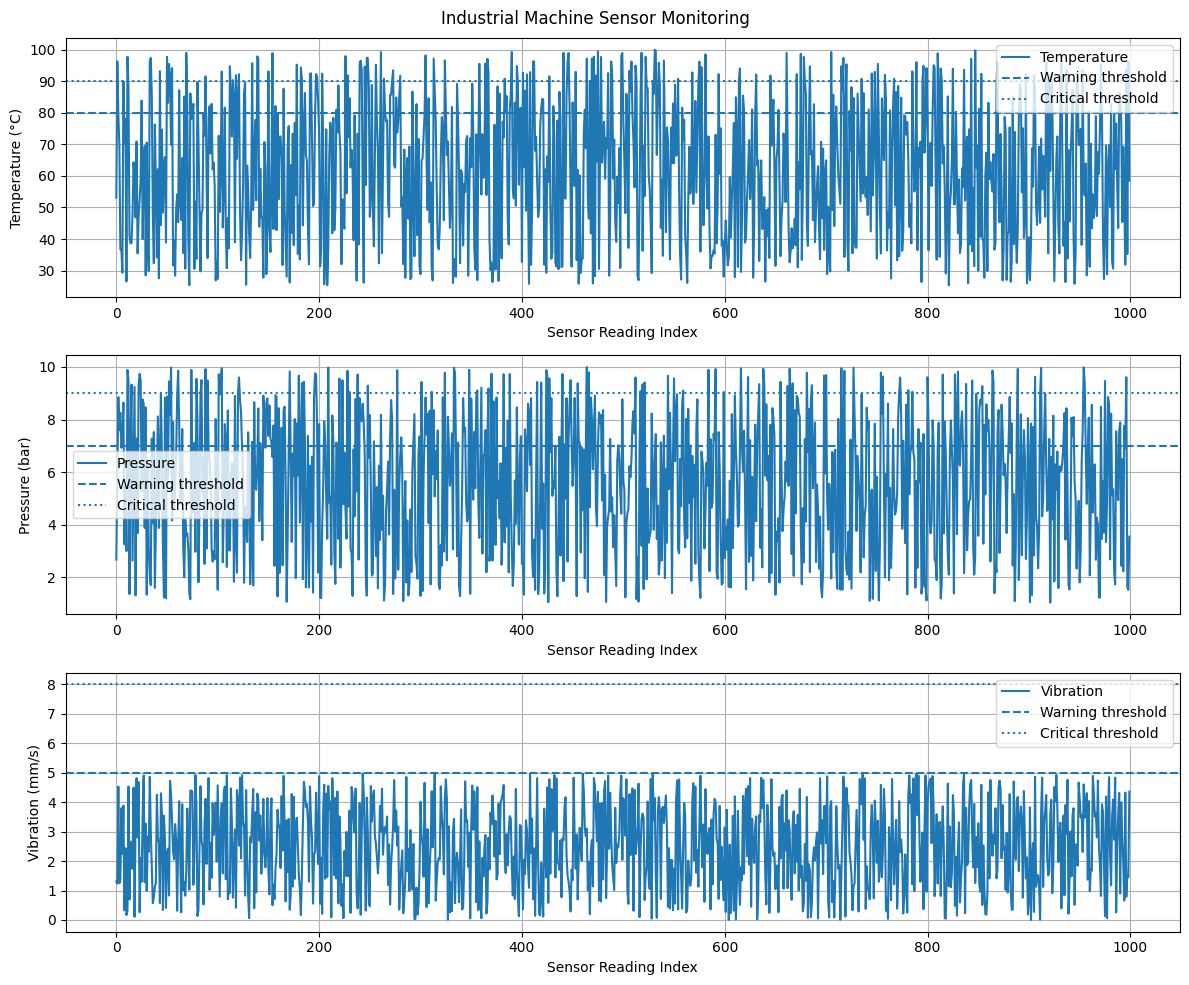


MONITORING SYSTEM COMPLETED
Total readings monitored: 1000
Abnormal readings: 505


In [13]:

# ============================================================
# MODULE 5: INDUSTRIAL MACHINE MONITORING AND ALERT SYSTEM
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Thresholds for demonstration purposes.
# Replace these with application-specific limits if available.

TEMP_WARNING = 80
TEMP_CRITICAL = 90

PRESSURE_WARNING = 7
PRESSURE_CRITICAL = 9

VIBRATION_WARNING = 5
VIBRATION_CRITICAL = 8


# ------------------------------------------------------------
# 1. MONITOR SENSOR READINGS
# ------------------------------------------------------------

monitoring_data = pd.DataFrame({
    "Temperature": temperature,
    "Pressure": pressure,
    "Vibration": vibration
})


# ------------------------------------------------------------
# 2. MACHINE CONDITION CLASSIFICATION
# ------------------------------------------------------------

def classify_machine(row):

    critical = (
        row["Temperature"] >= TEMP_CRITICAL or
        row["Pressure"] >= PRESSURE_CRITICAL or
        row["Vibration"] >= VIBRATION_CRITICAL
    )

    warning = (
        row["Temperature"] >= TEMP_WARNING or
        row["Pressure"] >= PRESSURE_WARNING or
        row["Vibration"] >= VIBRATION_WARNING
    )

    if critical:
        return "CRITICAL"

    elif warning:
        return "WARNING"

    return "NORMAL"


monitoring_data["Machine Status"] = (
    monitoring_data.apply(classify_machine, axis=1)
)


# ------------------------------------------------------------
# 3. GENERATE ALERTS
# ------------------------------------------------------------

print("=" * 65)
print("SMART MANUFACTURING MACHINE MONITORING SYSTEM")
print("=" * 65)

for i, row in monitoring_data.iterrows():

    if row["Machine Status"] != "NORMAL":

        print(
            f"Reading {i+1}: {row['Machine Status']} ALERT | "
            f"Temperature: {row['Temperature']:.2f} °C | "
            f"Pressure: {row['Pressure']:.2f} bar | "
            f"Vibration: {row['Vibration']:.2f} mm/s"
        )


# ------------------------------------------------------------
# 4. DISPLAY MACHINE STATUS SUMMARY
# ------------------------------------------------------------

status_counts = monitoring_data["Machine Status"].value_counts()

print("\nMACHINE STATUS SUMMARY")
print("-" * 65)

for status in ["NORMAL", "WARNING", "CRITICAL"]:

    print(
        status + ":",
        int(status_counts.get(status, 0))
    )


# ------------------------------------------------------------
# 5. SENSOR MONITORING GRAPHS
# ------------------------------------------------------------

fig, axes = plt.subplots(3, 1, figsize=(12, 10))

sensor_configs = [
    ("Temperature", TEMP_WARNING, TEMP_CRITICAL, "Temperature (°C)"),
    ("Pressure", PRESSURE_WARNING, PRESSURE_CRITICAL, "Pressure (bar)"),
    ("Vibration", VIBRATION_WARNING, VIBRATION_CRITICAL, "Vibration (mm/s)")
]

for ax, (column, warning, critical, ylabel) in zip(
    axes, sensor_configs
):

    ax.plot(
        monitoring_data[column],
        label=column,
        linewidth=1.5
    )

    ax.axhline(
        warning,
        linestyle="--",
        label="Warning threshold"
    )

    ax.axhline(
        critical,
        linestyle=":",
        label="Critical threshold"
    )

    ax.set_ylabel(ylabel)
    ax.set_xlabel("Sensor Reading Index")
    ax.grid(True)
    ax.legend()

plt.suptitle("Industrial Machine Sensor Monitoring")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. FINAL STATUS
# ------------------------------------------------------------

print("\nMONITORING SYSTEM COMPLETED")
print("Total readings monitored:", len(monitoring_data))
print("Abnormal readings:",
      int(len(monitoring_data) - status_counts.get("NORMAL", 0)))


RECEIVER-BASED INDUSTRIAL MONITORING
Transmitted packets: 1000
CRC-verified packets: 1000
Rejected packets: 0

MACHINE STATUS
-----------------------------------------------------------------
NORMAL : 495
CRITICAL : 225


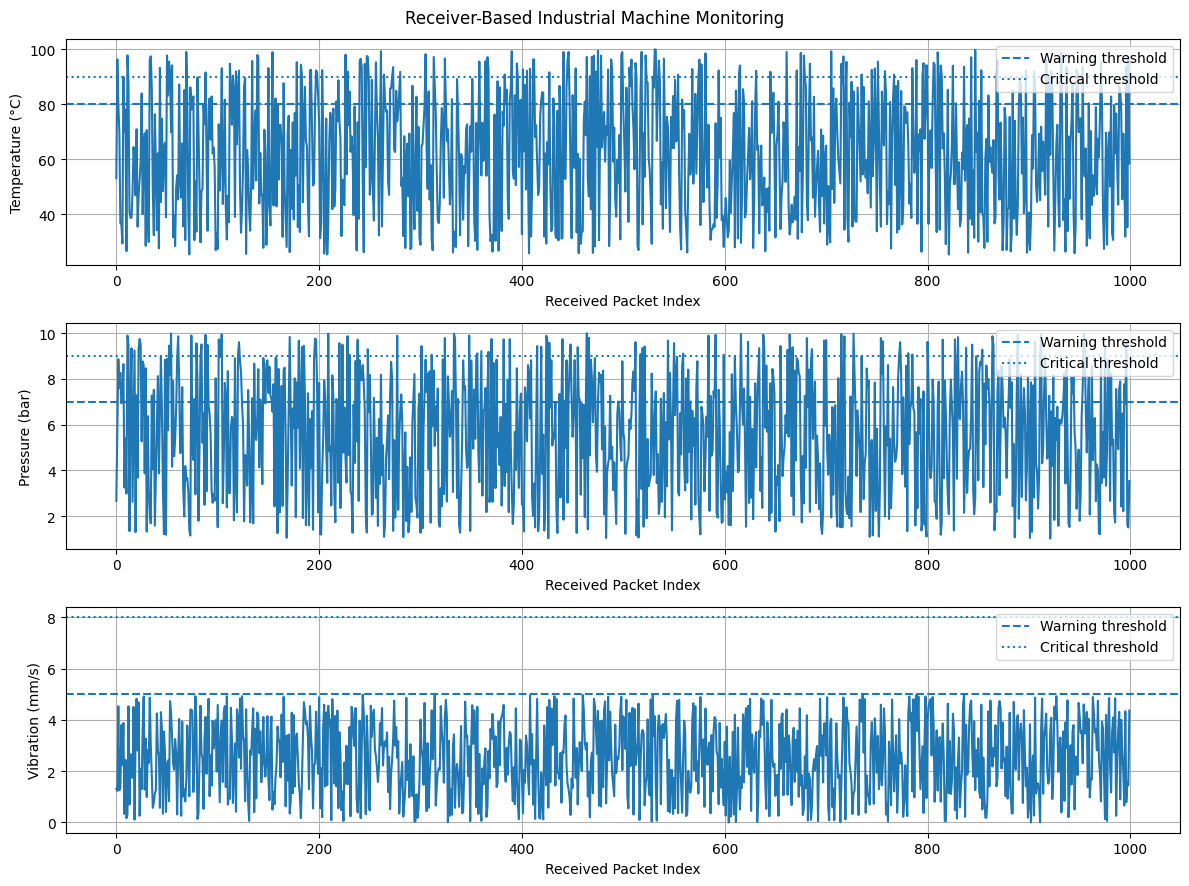


RECEIVER MONITORING COMPLETED


In [14]:

# ============================================================
# MODULE 6: RECEIVER-BASED INDUSTRIAL MONITORING
# Uses CRC-verified packets from the communication system
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import struct

# 1. EXTRACT ONLY CRC-VERIFIED RECEIVED PACKETS

verified_records = []

for packet in received_packets:

    if len(packet) == 11 and verify_crc(packet):

        # Remove the 2 CRC bytes
        payload = packet[:-2]

        machine_id, sequence, temp, press, vib = (
            struct.unpack(">BHHHH", payload)
        )

        verified_records.append({
            "Machine ID": machine_id,
            "Sequence": sequence,
            "Temperature": temp / 100,
            "Pressure": press / 100,
            "Vibration": vib / 100
        })


# 2. CREATE RECEIVER DATAFRAME

received_df = pd.DataFrame(verified_records)

# 3. CLASSIFY RECEIVED MACHINE CONDITIONS

def receiver_status(row):

    if (
        row["Temperature"] >= 90 or
        row["Pressure"] >= 9 or
        row["Vibration"] >= 8
    ):
        return "CRITICAL"

    elif (
        row["Temperature"] >= 80 or
        row["Pressure"] >= 7 or
        row["Vibration"] >= 5
    ):
        return "WARNING"

    return "NORMAL"


if len(received_df) > 0:

    received_df["Machine Status"] = (
        received_df.apply(receiver_status, axis=1)
    )

    # 4. DISPLAY RECEIVER RESULTS

    counts = received_df["Machine Status"].value_counts()

    print("=" * 65)
    print("RECEIVER-BASED INDUSTRIAL MONITORING")
    print("=" * 65)

    print("Transmitted packets:", len(packets_with_crc))
    print("CRC-verified packets:", len(received_df))
    print("Rejected packets:",
          len(packets_with_crc) - len(received_df))

    print("\nMACHINE STATUS")
    print("-" * 65)

    for status in ["NORMAL", "WARNING", "CRITICAL"]:
        print(status, ":", int(counts.get(status, 0)))

    # 5. DISPLAY RECEIVED SENSOR DATA

    fig, axes = plt.subplots(3, 1, figsize=(12, 9))

    configs = [
        ("Temperature", 80, 90, "Temperature (°C)"),
        ("Pressure", 7, 9, "Pressure (bar)"),
        ("Vibration", 5, 8, "Vibration (mm/s)")
    ]

    for ax, (column, warning, critical, ylabel) in zip(
        axes, configs
    ):

        ax.plot(received_df[column])
        ax.axhline(warning, linestyle="--",
                   label="Warning threshold")
        ax.axhline(critical, linestyle=":",
                   label="Critical threshold")

        ax.set_ylabel(ylabel)
        ax.set_xlabel("Received Packet Index")
        ax.legend()
        ax.grid(True)

    plt.suptitle("Receiver-Based Industrial Machine Monitoring")
    plt.tight_layout()
    plt.show()

    print("\nRECEIVER MONITORING COMPLETED")

else:
    print("No valid packets received. Monitoring unavailable.")


MULTI-SNR COMMUNICATION PERFORMANCE
 Eb/N0 (dB)      BER  Valid Packets  Rejected Packets  PDR (%)
          0 0.122875              0              1000      0.0
          2 0.055023             63               937      6.3
          4 0.015307            445               555     44.5
          6 0.002455            894               106     89.4
          8 0.000068            995                 5     99.5
         10 0.000000           1000                 0    100.0


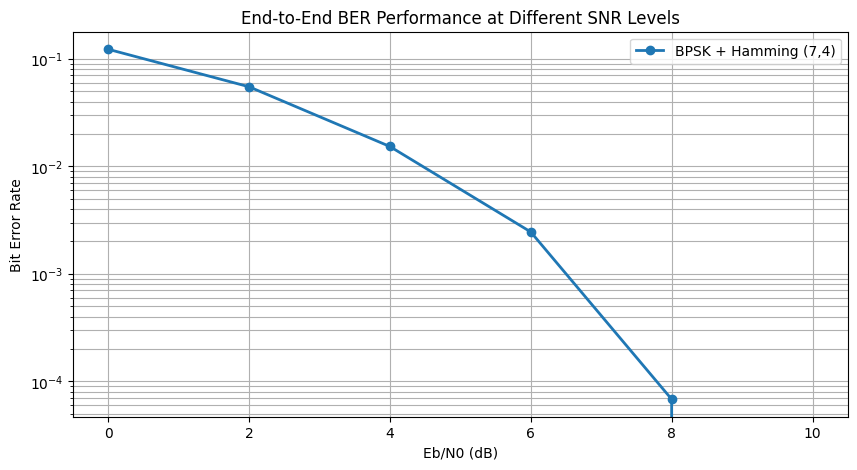

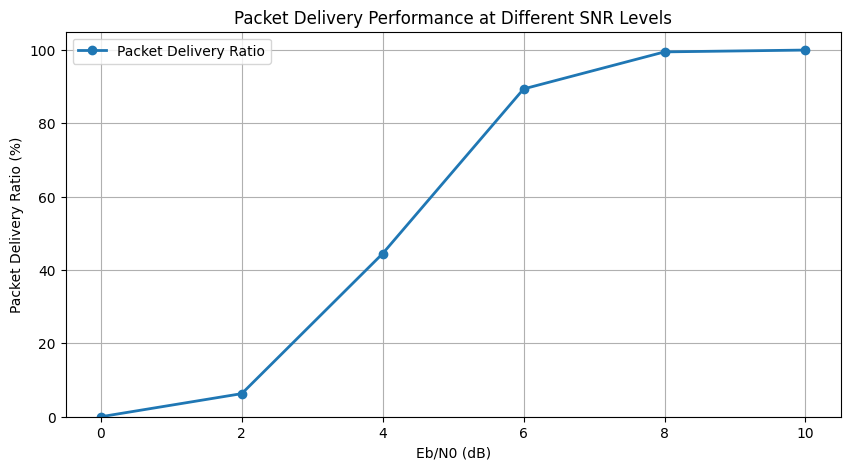


MULTI-SNR TEST COMPLETED


In [15]:

# ============================================================
# MODULE 7: MULTI-SNR COMMUNICATION PERFORMANCE TEST
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(100)

# Prepare original protected data
tx_data = b"".join(packets_with_crc)

tx_bits = np.unpackbits(
    np.frombuffer(tx_data, dtype=np.uint8)
).astype(int)

# Hamming encoding
encoded_bits, original_length = hamming_encode(tx_bits)

# Test SNR values
snr_values = [0, 2, 4, 6, 8, 10]

R = 4 / 7
total_packets = len(packets_with_crc)
packet_size = 11

results = []

# ============================================================
# TEST EACH SNR LEVEL
# ============================================================

for snr in snr_values:

    gamma = 10 ** (snr / 10)
    N0 = 1 / gamma

    # BPSK modulation
    tx_signal = np.sqrt(R) * bpsk_mod(encoded_bits)

    # AWGN channel
    noise = np.sqrt(N0 / 2) * np.random.randn(
        len(tx_signal)
    )

    rx_signal = tx_signal + noise

    # Demodulation
    received_encoded = (
        rx_signal >= 0
    ).astype(int)

    # Hamming decoding
    recovered_bits = hamming_decode(
        received_encoded.copy(),
        original_length
    )

    # BER calculation
    bit_errors = np.sum(tx_bits != recovered_bits)

    ber = bit_errors / len(tx_bits)

    # Reconstruct received bytes
    received_bytes = np.packbits(
        recovered_bits
    ).tobytes()

    received_packets = [
        received_bytes[i:i + packet_size]
        for i in range(0, len(received_bytes), packet_size)
    ]

    # CRC verification
    valid_packets = sum(
        1 for packet in received_packets
        if len(packet) == packet_size
        and verify_crc(packet)
    )

    rejected_packets = total_packets - valid_packets

    pdr = (valid_packets / total_packets) * 100

    results.append({
        "Eb/N0 (dB)": snr,
        "BER": ber,
        "Valid Packets": valid_packets,
        "Rejected Packets": rejected_packets,
        "PDR (%)": pdr
    })


# ============================================================
# DISPLAY RESULTS
# ============================================================

results_df = pd.DataFrame(results)

print("=" * 75)
print("MULTI-SNR COMMUNICATION PERFORMANCE")
print("=" * 75)

print(results_df.to_string(index=False))

# ============================================================
# BER GRAPH
# ============================================================

plt.figure(figsize=(10, 5))

plt.semilogy(
    results_df["Eb/N0 (dB)"],
    results_df["BER"],
    marker="o",
    linewidth=2,
    label="BPSK + Hamming (7,4)"
)

plt.xlabel("Eb/N0 (dB)")
plt.ylabel("Bit Error Rate")
plt.title("End-to-End BER Performance at Different SNR Levels")
plt.grid(True, which="both")
plt.legend()
plt.show()

# ============================================================
# PACKET DELIVERY GRAPH
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    results_df["Eb/N0 (dB)"],
    results_df["PDR (%)"],
    marker="o",
    linewidth=2,
    label="Packet Delivery Ratio"
)

plt.xlabel("Eb/N0 (dB)")
plt.ylabel("Packet Delivery Ratio (%)")
plt.title("Packet Delivery Performance at Different SNR Levels")
plt.ylim(0, 105)
plt.grid(True)
plt.legend()
plt.show()

print("\nMULTI-SNR TEST COMPLETED")
